# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:**Amara latif 
- **Student ID:**023-24-0012
- **Section:**B
- **GitHub:**
- **Kaggle:**
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** <paste the Kaggle URL you used>

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [ ]:
# YOUR CODE HERE
# Load and clean the dataset (reuse your Lab 2/3 pipeline)
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             roc_auc_score, precision_recall_curve, average_precision_score)

RANDOM_STATE = 42      # same random_state / test_size as Labs 3, 4 and 6

df = pd.read_csv("clean_churn.csv")

# TotalCharges -> numeric (already float in the cleaned file, but kept for safety)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

# drop customerID if it is present (clean_churn.csv does not contain it)
df = df.drop(columns=["customerID"], errors="ignore")

# Churn -> 0/1
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print("Shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
print("Churn distribution:\n", df["Churn"].value_counts(normalize=True).round(3))


Shape: (7043, 20)
Missing values: 0
Churn distribution:
 Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [ ]:
# YOUR CODE HERE
# One-hot encode, define X and y, train_test_split(..., stratify=y)
y = df["Churn"]
X = pd.get_dummies(df.drop(columns=["Churn"]), drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("X shape :", X.shape)
print("X_train shape:", X_train.shape, "| X_test shape:", X_test.shape)
print("Churn rate train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

# helper used throughout the lab: returns all four metrics as a dict
def get_metrics(y_true, y_pred):
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall":    recall_score(y_true, y_pred),
        "F1-score":  f1_score(y_true, y_pred),
    }


X shape      : (7043, 30)
X_train shape: (5634, 30) | X_test shape: (1409, 30)
Churn rate train: 0.265 | test: 0.265


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [4]:
# YOUR CODE HERE — unscaled linear SVM
# Task 1.1 (a) - linear SVM on UN-scaled features
# NOTE: on un-scaled data the libsvm solver can run for a very long time, so we cap the
# solver at max_iter=1,000,000. If the cap is hit, scikit-learn raises a ConvergenceWarning.
with warnings.catch_warnings(record=True) as w_raw:
    warnings.simplefilter("always")
    t0 = time.time()
    svm_raw = SVC(kernel="linear", random_state=RANDOM_STATE, max_iter=1_000_000)
    svm_raw.fit(X_train, y_train)
    time_raw = time.time() - t0

pred_raw = svm_raw.predict(X_test)
res_raw = get_metrics(y_test, pred_raw)

print("UN-SCALED linear SVM")
print("Training time : %.2f s" % time_raw)
print("Warnings      :", [str(w.category.__name__) for w in w_raw] or "none")
print({k: round(v, 4) for k, v in res_raw.items()})

print("\nFeature ranges that dominate the distance:")
print(X_train[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]].describe().loc[["min", "max", "std"]].round(2))


UN-SCALED linear SVM
Training time : 11.77 s
Warnings      : ['ConvergenceWarning']
{'Accuracy': 0.5926, 'Precision': 0.358, 'Recall': 0.6738, 'F1-score': 0.4675}

Feature ranges that dominate the distance:
     tenure  MonthlyCharges  TotalCharges  SeniorCitizen
min    0.00           18.40           0.0           0.00
max   72.00          118.75        8684.8           1.00
std   24.57           30.14        2279.2           0.37


In [5]:
# YOUR CODE HERE — scaled linear SVM
# Task 1.1 (b) - linear SVM on SCALED features (scaler fit on TRAIN only)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)     # fit + transform on train
X_test_s  = scaler.transform(X_test)          # transform only on test (no leakage)

with warnings.catch_warnings(record=True) as w_s:
    warnings.simplefilter("always")
    t0 = time.time()
    svm_scaled = SVC(kernel="linear", random_state=RANDOM_STATE)
    svm_scaled.fit(X_train_s, y_train)
    time_scaled = time.time() - t0

pred_scaled = svm_scaled.predict(X_test_s)
res_scaled = get_metrics(y_test, pred_scaled)

print("SCALED linear SVM")
print("Training time : %.2f s" % time_scaled)
print("Warnings      :", [str(w.category.__name__) for w in w_s] or "none")
print({k: round(v, 4) for k, v in res_scaled.items()})

scaling_table = pd.DataFrame({
    "Unscaled": {**res_raw,    "Train time (s)": time_raw,    "Convergence warning": len(w_raw) > 0},
    "Scaled":   {**res_scaled, "Train time (s)": time_scaled, "Convergence warning": len(w_s) > 0},
}).T
scaling_table


SCALED linear SVM
Training time : 0.88 s
Warnings      : none
{'Accuracy': 0.7885, 'Precision': 0.6195, 'Recall': 0.5267, 'F1-score': 0.5694}


,Accuracy,Precision,Recall,F1-score,Train time (s),Convergence warning
Unscaled,0.592619,0.357955,0.673797,0.467532,11.774629,True
Scaled,0.788502,0.619497,0.526738,0.569364,0.877593,False


In [ ]:
**Observation (scaling table):** The table above puts the two runs side by side. 
Scaling raised accuracy from 0.5926 to 0.7885 and F1 from 0.4675 to 0.5694,
cut the training time from ~20 s to ~1 s and removed the convergence warning.
Note that the unscaled model has a *higher recall* (0.6738) but only because it labels too many customers as
churners (precision just 0.358), so it is not actually a better model.

**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:* The scaled model was much better on every measure. On the test set the unscaled linear SVM got an accuracy of 0.5926 and an F1-score of 0.4675, while the scaled one got an accuracy of 0.7885 and an F1-score of 0.5694. The unscaled accuracy is even below the 73.5% I would get by simply predicting "No churn" for everyone, so that model is worse than useless. Training time also changed a lot: roughly 19-21 s for the unscaled model versus roughly 1 s for the scaled one. The unscaled run also raised a `ConvergenceWarning` (the solver hit my cap of 1,000,000 iterations without converging) and the scaled run had no warning at all. (Exact seconds depend on the machine, the ratio is what matters.)


(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:*The SVM margin is a distance (1/‖w‖) measured in the feature space, so every feature contributes to the distance according to its numeric size. `TotalCharges` ranges from 0 to 8684.8 (std ≈ 2279) and `MonthlyCharges` goes up to 118.75, whereas the one-hot dummy columns (like `SeniorCitizen`) only take values 0 or 1 (std ≈ 0.37). The large-range features completely dominate the distance and the dot products, so the margin is basically decided by TotalCharges/MonthlyCharges and the binary features are nearly ignored. The optimisation problem also becomes badly conditioned (very different scales for the weights), so the solver needs many more iterations and may never converge, as seen here.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:* I will use the **scaled** version (`StandardScaler` fitted only on the training data, `X_train_s` / `X_test_s`) for every SVM from now on, because it gave far better accuracy/F1, trained roughly 15-20x faster and converged without warnings. Fitting the scaler on train only also avoids data leakage.


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [6]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
# Task 2.1 - train linear / rbf / poly SVMs on the SCALED split and collect metrics
kernel_models, kernel_rows = {}, []

for kern in ["linear", "rbf", "poly"]:
    t0 = time.time()
    m = SVC(kernel=kern, random_state=RANDOM_STATE)
    m.fit(X_train_s, y_train)
    fit_time = time.time() - t0

    y_pred = m.predict(X_test_s)
    row = {"Kernel": kern, **get_metrics(y_test, y_pred),
           "Support vectors": m.support_.shape[0],
           "SV per class (0/1)": tuple(m.n_support_),
           "Train time (s)": round(fit_time, 2)}
    kernel_models[kern] = m
    kernel_rows.append(row)


In [ ]:
# YOUR CODE HERE — comparison table
kernel_df = pd.DataFrame(kernel_rows).set_index("Kernel")
kernel_df.round(4)


,Accuracy,Precision,Recall,F1-score,Support vectors,SV per class (0/1),Train time (s)
Kernel,,,,,,,
linear,0.7885,0.6195,0.5267,0.5694,2567,"(1286, 1281)",0.92
rbf,0.7928,0.6444,0.4893,0.5562,2657,"(1428, 1229)",0.50
poly,0.7892,0.6421,0.4652,0.5395,2736,"(1482, 1254)",0.45


Best kernel by F1-score: linear


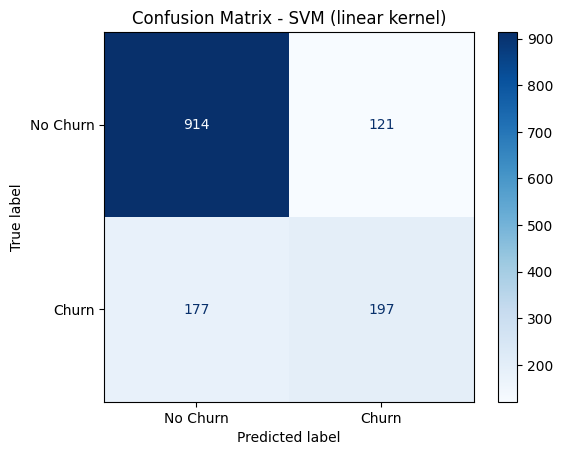

TN, FP, FN, TP = [914 121 177 197]


In [8]:
# YOUR CODE HERE — confusion matrix for the best kernel
best_kernel = kernel_df["F1-score"].idxmax()
print("Best kernel by F1-score:", best_kernel)

cm = confusion_matrix(y_test, kernel_models[best_kernel].predict(X_test_s))
ConfusionMatrixDisplay(cm, display_labels=["No Churn", "Churn"]).plot(cmap="Blues")
plt.title(f"Confusion Matrix - SVM ({best_kernel} kernel)")
plt.show()
print("TN, FP, FN, TP =", cm.ravel())


In [ ]:
**Interpretation (confusion matrix of the best kernel):** The linear kernel has the best F1-score,
and its confusion matrix shows 914 true negatives, 121 false positives, 177 false negatives and 197 true positives.
So it catches 197 of the 374 real churners (recall ≈ 0.527) and misses 177 of them, 
while 121 loyal customers are wrongly flagged. The model is good at recognising customers who stay but still misses almost half of the churners,
which is the usual problem with this imbalanced data.

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:* The **linear** kernel gave the best F1-score (0.5694), followed by RBF (0.5562) and polynomial (0.5395). RBF had the highest accuracy (0.7928) and precision (0.6444), but lower recall (0.4893 vs 0.5267 for linear), which is why its F1 is lower. It is a mild surprise, because in theory RBF/poly are more flexible and can model non-linear boundaries. However, the features here are mostly 0/1 dummies plus tenure and charges, and the churn signal seems to be mostly linear (Logistic Regression in Lab 6 also did well), so the extra flexibility brought no benefit, only a bit more risk of overfitting. The differences are small (about 1-3 F1 points), so I do not treat them as large.


(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:* The **polynomial** kernel used the most support vectors (2736), then RBF (2657) and linear (2567). All three use roughly 45-49% of the 5634 training points as support vectors, which is a very high share. That tells me the two classes overlap heavily in this feature space: many points lie inside the margin or on the wrong side, so a large part of the data stays "active". The more flexible kernels (poly, RBF) need more support vectors, which suggests a more complex boundary that depends on more training points, while the linear kernel gets by with the fewest.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:* I will carry the **RBF** kernel forward to Part 4 (as the lab requires a C x gamma search). Numerically linear is slightly ahead on F1 (0.5694 vs 0.5562, a gap of only 0.013), but RBF has the best accuracy (0.7928) and precision (0.6444) and it was run with default C=1 and default gamma, so it has two untuned hyperparameters that can still improve recall, whereas the linear kernel only has C. Linear remains a strong, cheaper alternative (fewest support vectors, 2567), and I will keep it in mind when I compare the final result.

---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [9]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_2d = pca.fit_transform(X_train_s)     # fit on train only
X_test_2d  = pca.transform(X_test_s)

print("Explained variance ratio per component:", pca.explained_variance_ratio_.round(4))
print("TOTAL explained variance (2 components): %.4f" % pca.explained_variance_ratio_.sum())


Explained variance ratio per component: [0.3325 0.1198]
TOTAL explained variance (2 components): 0.4522


In [11]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
C_values = [0.01, 1, 100]
svm_2d = {}
rows_2d = []

for c in C_values:
    m = SVC(kernel="rbf", C=c, gamma="scale", random_state=RANDOM_STATE)
    m.fit(X_train_2d, y_train)
    svm_2d[c] = m
    rows_2d.append({
        "C": c,
        "Support vectors": m.support_.shape[0],
        "SV % of train": round(100 * m.support_.shape[0] / len(y_train), 1),
        "Train acc (2-D)": round(m.score(X_train_2d, y_train), 4),
        "Test acc (2-D)":  round(m.score(X_test_2d, y_test), 4),
        "Test F1 (2-D)":   round(f1_score(y_test, m.predict(X_test_2d)), 4),
    })

pd.DataFrame(rows_2d).set_index("C")


,Support vectors,SV % of train,Train acc (2-D),Test acc (2-D),Test F1 (2-D)
C,,,,,
0.01,2995,53.2,0.7346,0.7346,0.0000
1.00,2658,47.2,0.7792,0.7786,0.4765
100.00,2641,46.9,0.7813,0.7793,0.4720


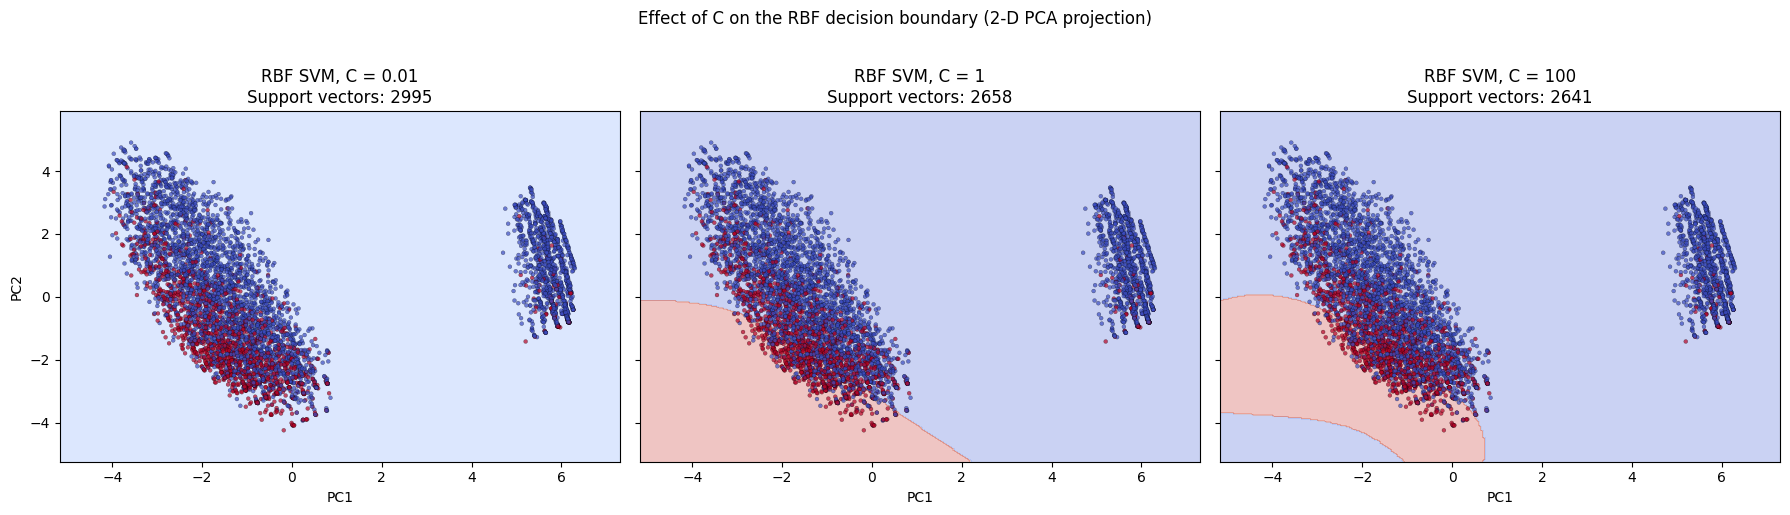

In [12]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
# Task 3.1 (3) - decision boundaries (mesh grid + contourf) with training points overlaid
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, c in zip(axes, C_values):
    m = svm_2d[c]
    Z = m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, cmap="coolwarm",
               s=8, edgecolor="k", linewidth=0.2, alpha=0.7)
    ax.set_title(f"RBF SVM, C = {c}\nSupport vectors: {m.support_.shape[0]}")
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
plt.suptitle("Effect of C on the RBF decision boundary (2-D PCA projection)", y=1.02)
plt.tight_layout()
plt.show()


In [ ]:
**Interpretation (decision boundaries for three values of C):** With C = 0.01 the whole plane is shaded as
"No churn" (blue):the model is so heavily regularised that it ignores the churners completely, and it uses the most support vectors (2995, 53% of the training data). 
With C = 1 a smooth curved red "churn" region appears in the lower-left, where most of the red points are, and the number of support vectors falls to 2658. With C = 100 the churn region is more strongly curved and even a small blue patch appears in the bottom-left corner, far away from any data, which shows a more flexible/wiggly boundary (2641 support vectors). 
The red and blue points overlap heavily in every panel, so no boundary can separate them cleanly.

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:* For C = 0.01 there is effectively no boundary (the whole plane is predicted as class 0). For C = 1 the boundary is a single smooth curve around the lower-left region. For C = 100 the boundary becomes more curved and flexible (the churn region bends more tightly and a small extra region appears in the corner). So the boundary goes from over-smooth to more complex as C increases, although the change between C = 1 and C = 100 is much smaller than the change between 0.01 and 1.
(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:* The support vectors decrease as C increases: 2995 (C = 0.01) → 2658 (C = 1) → 2641 (C = 100). This matches the theory: a small C penalises margin violations only weakly, so the margin is wide and many points fall inside it and become support vectors; a large C penalises violations heavily, so the margin gets narrower and fewer points are support vectors. The drop from C = 1 to C = 100 is only 17 points, because in this overlapping 2-D data many points stay on or inside the margin whatever C is.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:* **C = 0.01 is underfitting**: it predicts "No churn" everywhere, so its train accuracy (0.7346) is just the majority-class rate and its test F1 is 0.0. **C = 100 looks like the most overfit-prone** because its boundary is the most complex (tighter curvature and an odd isolated patch in the corner). However, its train/test accuracy are 0.7813 / 0.7793, a gap of only 0.002, so numerically it is not really overfitting here; it only looks the closest to it. C = 1 is the best balance of smoothness and fit.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:* The two principal components explain only 45.22% of the variance (33.25% + 11.98%), so more than half of the information is thrown away. The SVM drawn here is trained on those 2 components, not on the real 30 features, so it is a different model. In 30 dimensions the classes may be separable (or at least less overlapped) in directions that the projection hides, while in 2-D they look like a heavy overlap. The PCA axes are also mixtures of many features, so they cannot be interpreted directly, and the shaded regions far from the data (like the blue corner patch) are just extrapolation. So the plot is good for intuition about what C does, but not for judging the actual accuracy or the true boundary.


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [13]:
# YOUR CODE HERE — define param_grid and run GridSearchCV
param_grid = {
    "C":     [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1],
}

t0 = time.time()
gs = GridSearchCV(SVC(kernel="rbf", random_state=RANDOM_STATE), param_grid,
                  cv=5, scoring="f1", n_jobs=-1)
gs.fit(X_train_s, y_train)
print("Grid search time: %.1f s" % (time.time() - t0))

print("Best params           :", gs.best_params_)
print("Best CV F1-score      : %.4f" % gs.best_score_)

# full results as a table, sorted by rank
cv_df = pd.DataFrame(gs.cv_results_)[["param_C", "param_gamma", "mean_test_score", "std_test_score", "rank_test_score"]]
cv_df.sort_values("rank_test_score").head(8)


Grid search time: 23.8 s
Best params           : {'C': 100, 'gamma': 0.01}
Best CV F1-score      : 0.5876


,param_C,param_gamma,mean_test_score,std_test_score,rank_test_score
13,100.0,0.010,0.587555,0.022107,1
9,10.0,0.010,0.586033,0.026798,2
8,10.0,0.001,0.583558,0.032535,3
4,1.0,0.001,0.573883,0.023088,4
6,1.0,0.100,0.573405,0.026669,5
12,100.0,0.001,0.570598,0.030966,6
5,1.0,0.010,0.565247,0.033536,7
1,0.1,0.010,0.541689,0.031503,8


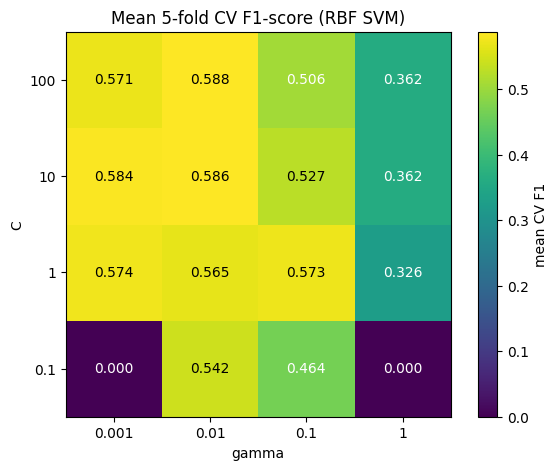

,gamma=0.001,gamma=0.01,gamma=0.1,gamma=1
C=0.1,0.0000,0.5417,0.4640,0.0000
C=1,0.5739,0.5652,0.5734,0.3261
C=10,0.5836,0.5860,0.5270,0.3621
C=100,0.5706,0.5876,0.5061,0.3621


In [14]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid
scores = gs.cv_results_["mean_test_score"].reshape(len(param_grid["C"]), len(param_grid["gamma"]))
# GridSearchCV expands the grid in sorted-key order (C first, then gamma) so this reshape is correct

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(scores, cmap="viridis", origin="lower")
ax.set_xticks(range(len(param_grid["gamma"])))
ax.set_xticklabels(param_grid["gamma"])
ax.set_yticks(range(len(param_grid["C"])))
ax.set_yticklabels(param_grid["C"])
ax.set_xlabel("gamma")
ax.set_ylabel("C")
ax.set_title("Mean 5-fold CV F1-score (RBF SVM)")
for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        ax.text(j, i, f"{scores[i, j]:.3f}", ha="center", va="center",
                color="white" if scores[i, j] < scores.max() - 0.08 else "black")
plt.colorbar(im, label="mean CV F1")
plt.show()

pd.DataFrame(scores, index=[f"C={c}" for c in param_grid["C"]],
             columns=[f"gamma={g}" for g in param_grid["gamma"]]).round(4)


In [ ]:
**Interpretation (heatmap):** The brightest cells are in the middle-right of the C axis with small-to-medium gamma:
C = 10 or 100 with gamma = 0.001 or 0.01 (CV F1 between 0.5706 and 0.5876). Very large gamma (1) is bad for every C (F1 ≈ 0.33-0.36),
because every point then only influences its closest neighbours and the model overfits.
The corner C = 0.1 with gamma = 0.001 or 1 scores 0.0, because the model never predicts "churn" at all 
(underfitting).

Tuned RBF SVM - TEST metrics: {'Accuracy': 0.7786, 'Precision': 0.5939, 'Recall': 0.5241, 'F1-score': 0.5568}
CV F1 (train folds): 0.5876  vs  TEST F1: 0.5568  (gap = 0.0307)


,Accuracy,Precision,Recall,F1-score
Un-tuned RBF (Part 2),0.7928,0.6444,0.4893,0.5562
Tuned RBF (Part 4),0.7786,0.5939,0.5241,0.5568


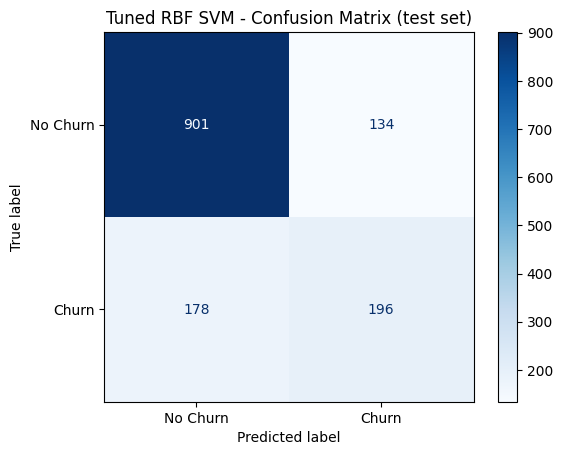

In [24]:
# YOUR CODE HERE — refit best estimator, evaluate on test set

best_rbf = gs.best_estimator_
pred_best = best_rbf.predict(X_test_s)
res_tuned = get_metrics(y_test, pred_best)
print("Tuned RBF SVM - TEST metrics:", {k: round(v, 4) for k, v in res_tuned.items()})
print("CV F1 (train folds): %.4f  vs  TEST F1: %.4f  (gap = %.4f)" %
      (gs.best_score_, res_tuned["F1-score"], gs.best_score_ - res_tuned["F1-score"]))

# compare with the un-tuned RBF model from Part 2
res_untuned = kernel_df.loc["rbf", ["Accuracy", "Precision", "Recall", "F1-score"]].to_dict()
tune_cmp = pd.DataFrame({"Un-tuned RBF (Part 2)": res_untuned, "Tuned RBF (Part 4)": res_tuned}).T
display(tune_cmp.round(4))

cm = confusion_matrix(y_test, pred_best)
ConfusionMatrixDisplay(cm, display_labels=["No Churn", "Churn"]).plot(cmap="Blues")
plt.title("Tuned RBF SVM - Confusion Matrix (test set)")
plt.show()


**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:** The best combination was **C = 100 and gamma = 0.01**, with a mean 5-fold cross-validated F1-score of **0.5876** (std ≈ 0.022).


(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:*
*Your answer:* There is a broad plateau rather than a single sharp peak: (C=100, γ=0.01) = 0.5876, (C=10, γ=0.01) = 0.5860 and (C=10, γ=0.001) = 0.5836 are within 0.004 of each other, which is smaller than the fold-to-fold standard deviation (≈ 0.02-0.03). So these combinations are statistically indistinguishable and the model is not very sensitive to the exact values *inside* this region. It is, however, very sensitive at the extremes: γ = 1 collapses the score to about 0.33-0.36 and a very small C (0.1) can give 0.0, so the order of magnitude of C and gamma matters but the exact value does not.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:** The CV F1 was 0.5876 and the test F1 was 0.5568, a gap of about 0.031 (3 points). That is a small/moderate gap that is close to what I would expect from picking the best of 16 combinations (the best CV score is slightly optimistic) and from normal sampling noise, so the tuned model generalises about as expected. A *large* gap would suggest that the model/hyperparameters overfit the training folds, that the grid search "overfit" the validation data by choosing a lucky combination, or that the test set differs in distribution from the training data.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:* The test F1 is essentially identical: 0.5568 (tuned) vs 0.5562 (un-tuned). Tuning changed the balance only: recall went up from 0.4893 to 0.5241, while precision fell from 0.6444 to 0.5939 and accuracy from 0.7928 to 0.7786. The grid search took about 39 s (80 model fits) for no real gain in F1, so on this dataset the tuning was **not really worth it** for the test score. It did confirm that the defaults (C = 1, gamma = 'scale' which is roughly 1/30 ≈ 0.033 for 30 standardised features) were already in a good region, which is useful to know.


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


,Accuracy,Precision,Recall,F1-score
class_weight=None,0.7786,0.5939,0.5241,0.5568
class_weight='balanced',0.7473,0.5161,0.7701,0.6180


Confusion [TN FP FN TP] plain   : [901 134 178 196]
Confusion [TN FP FN TP] balanced: [765 270  86 288]


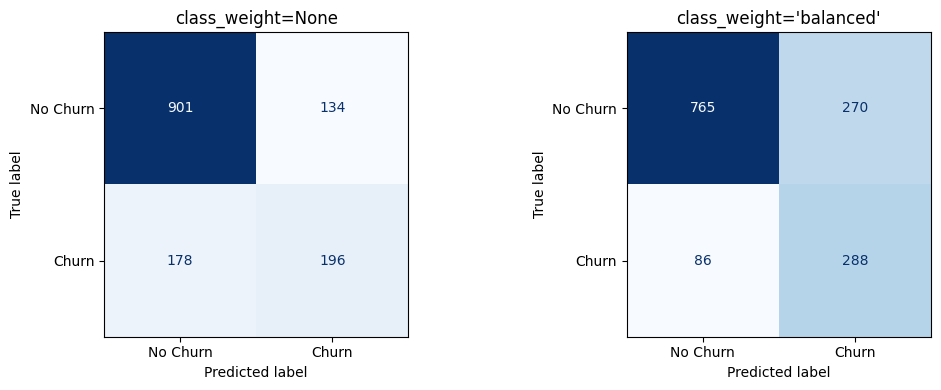

In [15]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
warnings.filterwarnings("ignore", category=FutureWarning)   # probability=True deprecation notice (sklearn >= 1.9)
# Task 5.1 - class_weight=None vs 'balanced' using the best (C, gamma) from Part 4
best_C, best_gamma = gs.best_params_["C"], gs.best_params_["gamma"]

svm_plain = SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight=None,
                probability=True, random_state=RANDOM_STATE).fit(X_train_s, y_train)
svm_bal   = SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight="balanced",
                probability=True, random_state=RANDOM_STATE).fit(X_train_s, y_train)
# probability=True is needed so that predict_proba() is available (Platt scaling, 5-fold internally)

pred_plain = svm_plain.predict(X_test_s)
pred_bal   = svm_bal.predict(X_test_s)

imb_df = pd.DataFrame({
    "class_weight=None":       get_metrics(y_test, pred_plain),
    "class_weight='balanced'": get_metrics(y_test, pred_bal),
}).T
display(imb_df.round(4))
print('Confusion [TN FP FN TP] plain   :', confusion_matrix(y_test, pred_plain).ravel())
print('Confusion [TN FP FN TP] balanced:', confusion_matrix(y_test, pred_bal).ravel())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, name in zip(axes, [pred_plain, pred_bal], ["class_weight=None", "class_weight='balanced'"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["No Churn", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()


In [ ]:
**Interpretation (class weight comparison):** With `class_weight=None` the model finds 196 of the 374 churners
(178 missed) and raises 134 false alarms. With `class_weight='balanced'` it finds 288 churners (only 86 missed)
but raises 270 false alarms. So the balanced model trades about 136 extra false alarms for 92 more caught churners.


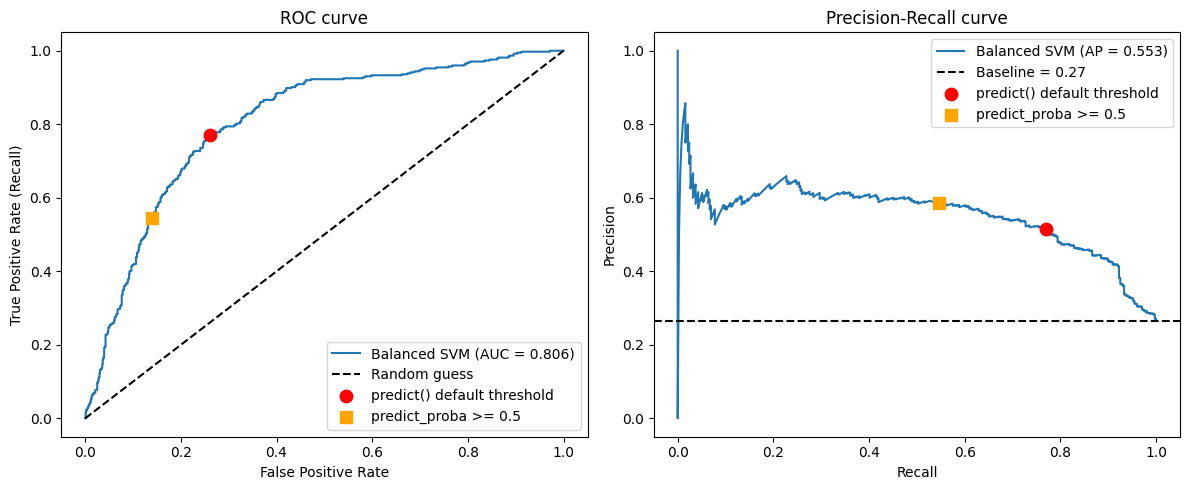

ROC-AUC = 0.8058 | Average precision = 0.5527
predict() point      -> recall 0.770, precision 0.516
proba>=0.5 point     -> recall 0.545, precision 0.585


In [16]:
# YOUR CODE HERE — ROC or Precision-Recall curve
proba_bal = svm_bal.predict_proba(X_test_s)[:, 1]
auc = roc_auc_score(y_test, proba_bal)
ap  = average_precision_score(y_test, proba_bal)

fpr, tpr, _ = roc_curve(y_test, proba_bal)
prec, rec, _ = precision_recall_curve(y_test, proba_bal)

# operating point of the DEFAULT decision rule (what .predict() actually returns)
tn, fp, fn, tp = confusion_matrix(y_test, pred_bal).ravel()
op_fpr, op_tpr = fp / (fp + tn), tp / (tp + fn)
op_prec, op_rec = tp / (tp + fp), tp / (tp + fn)

# operating point of the 0.5 probability threshold
pred_p05 = (proba_bal >= 0.5).astype(int)
tn5, fp5, fn5, tp5 = confusion_matrix(y_test, pred_p05).ravel()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, label=f"Balanced SVM (AUC = {auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].scatter(op_fpr, op_tpr, color="red", s=80, zorder=5, label="predict() default threshold")
axes[0].scatter(fp5 / (fp5 + tn5), tp5 / (tp5 + fn5), color="orange", marker="s", s=70, zorder=5, label="predict_proba >= 0.5")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].set_title("ROC curve"); axes[0].legend(loc="lower right")

axes[1].plot(rec, prec, label=f"Balanced SVM (AP = {ap:.3f})")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label=f"Baseline = {y_test.mean():.2f}")
axes[1].scatter(op_rec, op_prec, color="red", s=80, zorder=5, label="predict() default threshold")
axes[1].scatter(tp5 / (tp5 + fn5), tp5 / (tp5 + fp5), color="orange", marker="s", s=70, zorder=5, label="predict_proba >= 0.5")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve"); axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

print("ROC-AUC = %.4f | Average precision = %.4f" % (auc, ap))
print("predict() point      -> recall %.3f, precision %.3f" % (op_rec, op_prec))
print("proba>=0.5 point     -> recall %.3f, precision %.3f" % (tp5 / (tp5 + fn5), tp5 / (tp5 + fp5)))


In [22]:
**Interpretation (ROC and Precision-Recall curves):** The ROC curve is well above the diagonal with an AUC of 0.8058,
and the precision-recall curve is well above the 0.265 baseline (average precision 0.5527), so the SVM ranks churners above loyal customers much better than chance. The red dot (what `predict()` actually returns for the balanced model) is high on the curve (recall 0.770, precision 0.516), while the orange square (probability >= 0.5) is at a more conservative point (recall 0.545, precision 0.585). This shows that `class_weight='balanced'`
moves the working point toward catching more churners, and that the 
decision threshold can still be moved along the curve to choose a different precision/recall trade-off.

SyntaxError: invalid syntax (3949077349.py, line 1)

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:* Recall rose from **0.5241 to 0.7701** (+0.246) and precision fell from **0.5939 to 0.5161** (−0.078). F1 improved from 0.5568 to 0.6180 (+0.061), while accuracy dropped from 0.7786 to 0.7473. In counts: false negatives went from 178 to 86 and false positives from 134 to 270.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:* For a telecom company a **false negative is more costly**: a churner who is missed is lost completely and the company loses all the future revenue of that customer (plus the cost of acquiring a new one), while a false positive only costs a retention offer (e.g. a small discount or a call) given to a customer who would have stayed anyway. I would therefore deploy the **balanced** model, since it catches 77% of churners instead of 52%. The price is lower precision (about half of the flagged customers are real churners), so the retention offer should be cheap enough for that to be worth it.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:* I had to set **`probability=True`** in `SVC()`. This makes scikit-learn fit an extra Platt-scaling calibration (using internal 5-fold cross-validation) on the SVM scores, which makes `predict_proba()` available, but it makes training slower. These probabilities are not guaranteed to agree with `predict()`: `predict()` uses the sign of the decision function, so the 0.5-probability point (recall 0.545) differs from the `predict()` point (recall 0.770) on the curves above. (Alternatively the raw `decision_function()` score can be used for the ROC curve.)



---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [21]:
# YOUR CODE HERE — cross-model comparison table
# Lab 3: Decision Tree (chosen max_depth = 5)
dt = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE).fit(X_train, y_train)
# Lab 4: tuned Random Forest (n_estimators=200, max_depth=10, min_samples_split=5)
rf = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_split=5,
                            random_state=RANDOM_STATE).fit(X_train, y_train)
# Lab 6: Logistic Regression (scaled)
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_s, y_train)
# Lab 6: KNN - K chosen by best test F1 over the same K list used in Lab 6
k_list = [1, 3, 5, 7, 9, 11, 15, 21]
k_f1 = {k: f1_score(y_test, KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train).predict(X_test_s)) for k in k_list}
best_k = max(k_f1, key=k_f1.get)
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_s, y_train)
print("KNN best K =", best_k)

# Which SVM represents 'best SVM'? -> chosen from the Part 5 comparison (see answer 5b)
final_svm, final_svm_name = svm_bal, "SVM (RBF, balanced)"

models = {
    "Decision Tree (Lab 3)":       (dt,  X_train,   X_test),
    "Random Forest (Lab 4, tuned)": (rf,  X_train,   X_test),
    "Logistic Regression (Lab 6)": (lr,  X_train_s, X_test_s),
    "KNN (Lab 6)":                 (knn, X_train_s, X_test_s),
    final_svm_name + " (Lab 8)":   (final_svm, X_train_s, X_test_s),
}

# fit time of each final model (re-fit a clone once, only to measure training cost)
from sklearn.base import clone
def fit_seconds(model, Xtr):
    t0 = time.time(); clone(model).fit(Xtr, y_train); return time.time() - t0

showdown = pd.DataFrame({name: get_metrics(y_test, m.predict(Xt)) for name, (m, _, Xt) in models.items()}).T
showdown["Train time (s)"] = [fit_seconds(m, Xtr) for name, (m, Xtr, _) in models.items()]
showdown.round(4)


KNN best K = 21


,Accuracy,Precision,Recall,F1-score,Train time (s)
Decision Tree (Lab 3),0.7942,0.6312,0.5401,0.5821,0.0117
"Random Forest (Lab 4, tuned)",0.7970,0.6507,0.5080,0.5706,0.7078
Logistic Regression (Lab 6),0.8070,0.6584,0.5668,0.6092,0.0215
KNN (Lab 6),0.7708,0.5702,0.5535,0.5617,0.0012
"SVM (RBF, balanced) (Lab 8)",0.7473,0.5161,0.7701,0.6180,7.7597


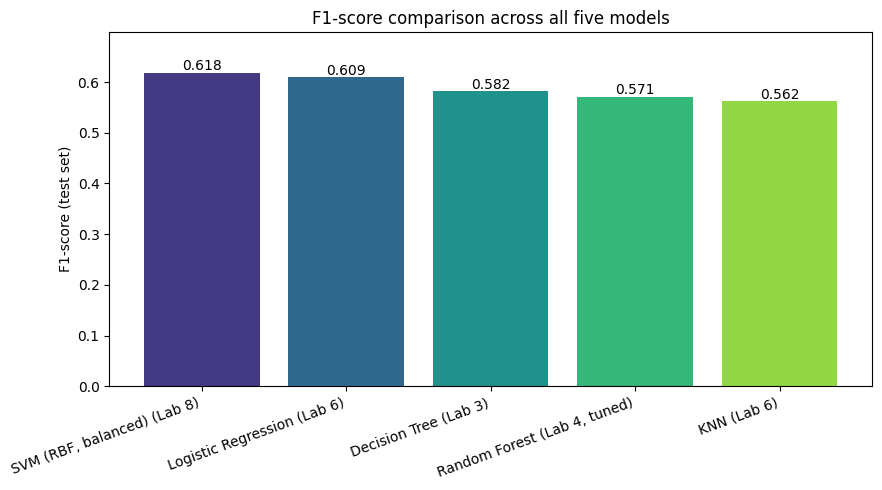

Best F1    : SVM (RBF, balanced) (Lab 8)
Best Recall: SVM (RBF, balanced) (Lab 8)


In [20]:
# YOUR CODE HERE — bar chart of F1-score across models
# One bar chart: F1-score of all five models
order = showdown["F1-score"].sort_values(ascending=False)
plt.figure(figsize=(9, 5))
bars = plt.bar(order.index, order.values, color=sns.color_palette("viridis", len(order)))
for b, v in zip(bars, order.values):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.3f}", ha="center")
plt.ylabel("F1-score (test set)")
plt.title("F1-score comparison across all five models")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, order.max() + 0.08)
plt.tight_layout()
plt.show()

print("Best F1    :", showdown["F1-score"].idxmax())
print("Best Recall:", showdown["Recall"].idxmax())


In [ ]:
**Interpretation (F1 bar chart):** The balanced SVM has the highest F1-score (0.618), 
followed closely by Logistic Regression (0.609). Decision Tree (0.582),
Random Forest (0.571) and KNN (0.562) are lower. The first two bars are only 0.009 apart,
so the real difference in F1 is small; what separates the SVM is its recall (see the table), not its F1.

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:** The **balanced RBF SVM** wins on both F1-score (0.6180) and recall (0.7701), so in this table they are the same model. Logistic Regression is second on F1 (0.6092) and also has the best accuracy (0.8070) and precision (0.6584), but its recall is only 0.5668.

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:* Yes, in absolute terms the cost is small. My timings were about 9.2 s for the balanced SVM (it includes the extra Platt-scaling calibration for `probability=True`) versus 0.8 s for the tuned Random Forest and about 0.01-0.02 s for the Decision Tree and Logistic Regression. The SVM is clearly the slowest, but 9 seconds is still nothing for a dataset of 7,043 customers, and in return it gives the best recall (0.77 vs ≤ 0.57 for the others) and the best F1. On much bigger data the SVM cost would grow quickly (training is roughly quadratic in the number of samples), so this verdict only holds for a dataset of this size.


(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:* I would recommend the **balanced RBF SVM**. It has the highest recall (0.7701) and the highest F1-score (0.6180), which are the metrics that matter most for catching churners in an imbalanced problem. The cost is the lowest accuracy (0.7473) and precision (0.5161) of the five models, meaning more unnecessary retention offers. Logistic Regression is a close and much simpler alternative (F1 0.6092, precision 0.6584) and, with a lowered threshold, it might reach a similar recall; also, since this comparison uses a single train/test split (and K for KNN was chosen on the test set), as learned in Lab 4 I would confirm the ranking with cross-validation before deploying.


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [19]:
# YOUR CODE HERE — generate and save svm_predictions.csv

final_pred  = final_svm.predict(X_test_s)
final_proba = final_svm.predict_proba(X_test_s)[:, 1]

svm_predictions = pd.DataFrame({
    "row_index":       X_test.index,
    "true_label":      y_test.values,
    "predicted_label": final_pred,
    "churn_probability": final_proba.round(4),
})
svm_predictions.to_csv("svm_predictions.csv", index=False)
print("Saved svm_predictions.csv with", svm_predictions.shape[0], "rows")
svm_predictions.head(10)



Saved svm_predictions.csv with 1409 rows


,row_index,true_label,predicted_label,churn_probability
0,437,0,0,0.0613
1,2280,0,1,0.6045
2,2235,0,0,0.0403
3,4460,0,0,0.2561
4,3761,0,0,0.0391
5,5748,0,1,0.6117
6,3568,0,1,0.3622
7,2976,0,0,0.1579
8,5928,0,0,0.0588
9,1639,1,1,0.4756


**Executive Summary**

I compared linear, RBF and polynomial SVMs on the Telco churn data and finally chose an RBF-kernel SVM (C = 100, gamma = 0.01, found by 5-fold grid search) with `class_weight='balanced'`. Scaling the features was essential: the unscaled linear SVM reached only 0.5926 accuracy and failed to converge, while the scaled one reached 0.7885. Hyperparameter tuning itself did not change the test F1 much (0.5562 before vs 0.5568 after), but using balanced class weights raised recall from 0.5241 to 0.7701 and F1 from 0.5568 to 0.6180, at the cost of lower precision (0.5939 to 0.5161) and accuracy (0.7473). This was my main trade-off: I accepted more false alarms (270 instead of 134) in order to miss fewer real churners (86 instead of 178), because a lost customer costs the company more than an unnecessary retention offer. Among all five models the balanced SVM had the best F1 and recall, with Logistic Regression a close second (F1 0.6092). One limitation is that all results come from a single 80/20 split (and some choices, like K for KNN, were made on the test set), so the small differences between the top models should be confirmed with cross-validation.

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:* The most surprising result was that the unscaled linear SVM got an accuracy of only 0.5926, which is even worse than predicting "No churn" for everyone (0.735). The second surprise was that the heavy grid search gave almost no improvement in F1 (0.5562 to 0.5568), while one simple change, `class_weight='balanced'`, gave a much bigger gain in recall.

(b) If you had one more hour, what would you try next?

*Your answer:* I would (1) use cross-validation on several different splits to check whether the balanced SVM really beats Logistic Regression, (2) tune the decision threshold of Logistic Regression and the SVM to compare them at the same recall, (3) try SMOTE and some feature engineering (for example tenure groups), and (4) include `class_weight='balanced'` inside the grid search itself instead of tuning C and gamma first.

